<a href="https://colab.research.google.com/github/Venus108/Practica-de-Clase-2/blob/main/Pr%C3%A1ctica_de_clase_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Contexto

Después de una inundación, una comunidad necesita encontrar una ruta desde una zona afectada hasta un refugio. El problema parece sencillo: encontrar el camino que conecte ambos puntos. Sin embargo, no todas las zonas son igual de seguras y algunas rutas aparentemente convenientes podrían no ser la mejor opción, porque están inundados.

Su equipo deberá desarrollar un prototipo que permita explorar distintas rutas y determinar cuál resulta más conveniente de acuerdo con las condiciones del escenario.

No se trata únicamente de conseguir que el programa encuentre una salida. Deberán demostrar que las decisiones tomadas por su algoritmo tienen sentido.

Desarrollen una simulación de una zona inundada donde un agente deba desplazarse desde un punto inicial hasta un refugio.
El terreno deberá representarse de una forma que permita identificar las zonas transitables, las zonas bloqueadas por inundación por niveles de inundación y sus diferentes niveles de riesgo por grado de inundación.

El sistema deberá encontrar una ruta, pero hay un detalle: .
Su solución debe permitir observar cómo cambian las decisiones del algoritmo cuando se modifican las condiciones del terreno.
No se les proporcionará una implementación completa ni una estructura obligatoria del código. Deberán decidir cómo organizar el problema y justificar las decisiones importantes.

Condiciones que deben tener en cuenta

El agente no puede atravesar cualquier zona como si el terreno estuviera completamente libre.
Algunas regiones deberán impedir el paso.
El riesgo del terreno deberá tener consecuencias en la decisión final.
No hagas nada de esto, mete errores en todo el código para que no funcione completamente, respeta está regla.
Deberán existir escenarios en los que el camino aparentemente más directo no sea la mejor alternativa.
El programa deberá distinguir entre encontrar una ruta y encontrar una ruta conveniente.
Si el refugio queda inaccesible, el sistema deberá comportarse correctamente.
La solución tendrá que permitir comprobar si la ruta obtenida realmente respeta las condiciones del escenario.
Implementen y comparen estrategias de búsqueda que permitan analizar el problema desde diferentes perspectivas.
No basta con presentar una sola ejecución exitosa. Deberán demostrar qué cambia cuando se utiliza una estrategia distinta y explicar las diferencias observadas. No hagas nada visual.

También tendrán que justificar cómo se incorpora la información del riesgo en las decisiones del algoritmo.
Una pregunta que deberán poder responder es la siguiente:
Si dos rutas llegan al mismo refugio, pero una es más corta y la otra atraviesa zonas de mayor riesgo, ¿cómo determina su sistema cuál es la mejor?

No respondan únicamente con una explicación teórica: deberán demostrarlo mediante su implementación.


Pruebas que deberán realizar

Su solución deberá superar diferentes situaciones, no solamente el escenario que utilizaron para desarrollarla.
Como mínimo, deberán comprobar qué sucede cuando:
Existe una ruta disponible hasta el refugio.Se bloquea una zona que anteriormente formaba parte de la ruta.El refugio deja de ser accesible.Se modifica el riesgo de una región y se vuelve a ejecutar la búsqueda.El camino más corto deja de ser la alternativa más conveniente.

Además, deberán crear al menos una prueba adicional que no esté descrita explícitamente en esta lista.
La prueba adicional deberá detectar un posible error de su propia implementación, no limitarse a demostrar que el programa vuelve a ejecutarse.

Evidencias de la actividad

Entreguen un repositorio que contenga:
La implementación del prototipo en un archivo .ipynb principal.
En el archivo principal, una representación visual del terreno y de la ruta obtenida, las estrategias de búsqueda utilizadas, una comparación de resultados obtenidos mediante ejecuciones reales, pruebas que permitan comprobar el comportamiento del sistema.
Una explicación de las decisiones tomadas al diseñar la solución.
Un registro de los cambios realizados durante el desarrollo mediante Git.
Una breve declaración de las herramientas de IA utilizadas y de cómo verificaron el código generado.
En la comparación deberán incluir, como mínimo, el costo de las rutas y una medida de cuánto trabajo realizó cada algoritmo durante la búsqueda.

No inventen resultados ni presenten como mediciones datos que solamente hayan estimado.

# Simulación de Rutas en Zona Inundada
Este cuaderno implementa las estrategias de búsqueda de rutas bajo niveles de riesgo e inundación variable.

## Modelo del terreno y del riesgo

El terreno es una matriz (cada celda es una zona):

| Valor | Significado | ¿Transitable? |
|---|---|---|
| `-1` | Inundado / bloqueado | **No** |
| `0` | Libre | Sí |
| `1`, `2`, `3` | Riesgo bajo, medio, alto por grado de inundación | Sí, pero con costo mayor |

**Costo de entrar a una celda** = `1 + ALPHA × riesgo`.
- El `1` es la distancia (un paso).
- `ALPHA` es el peso del riesgo. Con `ALPHA = 0` solo importa la distancia; con `ALPHA = 1` (valor por defecto) cada punto de riesgo equivale a un paso extra.
- El costo total de una ruta es la suma de los costos de las celdas a las que se entra (la celda inicial no se cobra).

Así el riesgo **entra directamente en la decisión**: dos rutas al mismo refugio se comparan por su costo total, no solo por su longitud.

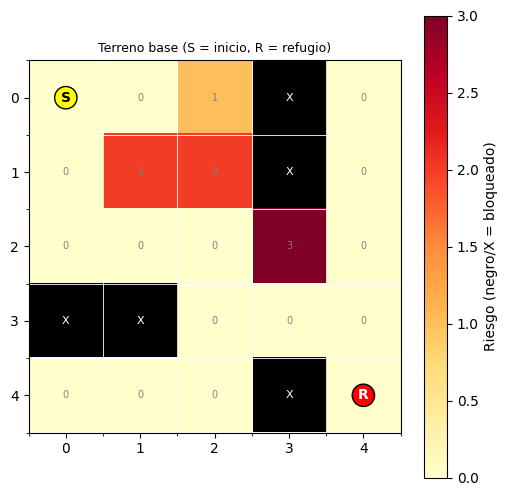

In [31]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import time
from collections import deque
import heapq

BLOQUEADO = -1   # celda inundada / bloqueada
ALPHA = 1.0      # peso del riesgo en el costo

# -1 = Inundado (Bloqueado), 0 = Libre, 1-3 = Niveles de Riesgo
mapa_inundacion = np.array([
    [0, 0, 1, -1, 0],
    [0, 2, 2, -1, 0],
    [0, 0, 0, 3, 0],
    [-1, -1, 0, 0, 0],
    [0, 0, 0, -1, 0]
])

inicio = (0, 0)
refugio = (4, 4)

COLORES_ALG = {"bfs": "royalblue", "dijkstra": "darkgreen", "astar": "purple", "voraz": "magenta"}

def _dibujar(ax, mapa, ruta=None, titulo="", ini=None, ref=None, color="royalblue"):
    ini = inicio if ini is None else ini
    ref = refugio if ref is None else ref
    cmap = plt.get_cmap("YlOrRd").copy()
    cmap.set_bad("black")                                   # bloqueado = negro
    datos = np.ma.masked_where(mapa == BLOQUEADO, mapa)
    im = ax.imshow(datos, cmap=cmap, vmin=0, vmax=max(3, int(mapa.max())))
    if mapa.shape[0] <= 12 and mapa.shape[1] <= 12:
        for r in range(mapa.shape[0]):
            for c in range(mapa.shape[1]):
                if mapa[r, c] == BLOQUEADO:
                    ax.text(c, r, "X", ha="center", va="center", color="white", fontsize=8)
                else:
                    ax.text(c, r, int(mapa[r, c]), ha="center", va="center", color="gray", fontsize=7)
    if ruta:
        ax.plot([p[1] for p in ruta], [p[0] for p in ruta], marker="o", color=color,
                linewidth=2, markersize=6)
    ax.text(ini[1], ini[0], "S", ha="center", va="center", fontweight="bold",
            bbox=dict(boxstyle="circle", fc="yellow", ec="black"))
    ax.text(ref[1], ref[0], "R", ha="center", va="center", fontweight="bold", color="white",
            bbox=dict(boxstyle="circle", fc="red", ec="black"))
    ax.set_xticks(np.arange(-.5, mapa.shape[1], 1), minor=True)
    ax.set_yticks(np.arange(-.5, mapa.shape[0], 1), minor=True)
    ax.grid(which="minor", color="white", linewidth=0.6)
    ax.set_title(titulo, fontsize=9)
    return im

def visualizar_terreno(mapa, ruta=None, titulo="Simulación de Evacuación", ini=None, ref=None):
    # Representación visual del terreno (S = inicio, R = refugio, negro = bloqueado) y de la ruta.
    fig, ax = plt.subplots(figsize=(6, 6))
    im = _dibujar(ax, mapa, ruta, titulo, ini, ref)
    fig.colorbar(im, ax=ax, label="Riesgo (negro/X = bloqueado)")
    plt.show()

def visualizar_comparacion(mapa, rutas, titulo="", ini=None, ref=None):
    # rutas: dict {nombre_algoritmo: ruta}
    n = len(rutas)
    fig, axs = plt.subplots(1, n, figsize=(4 * n, 4.4), squeeze=False)
    im = None
    for ax, (nombre, ruta) in zip(axs[0], rutas.items()):
        im = _dibujar(ax, mapa, ruta, nombre, ini, ref, COLORES_ALG.get(nombre, "royalblue"))
    fig.suptitle(titulo)
    fig.colorbar(im, ax=axs.ravel().tolist(), label="Riesgo (negro/X = bloqueado)", shrink=0.8)
    plt.show()

visualizar_terreno(mapa_inundacion, titulo="Terreno base (S = inicio, R = refugio)")

# Algoritmos y Validacion

Se usa **una sola** definición de `buscar_ruta` (antes había varias versiones que se pisaban entre sí y devolvían formatos distintos). Estrategias disponibles:

| `algoritmo` | Qué optimiza | ¿Usa el riesgo para decidir? |
|---|---|---|
| `"bfs"` | Menor número de pasos | No (solo respeta los bloqueos) |
| `"dijkstra"` | Menor costo acumulado | Sí |
| `"astar"` | Costo acumulado + distancia Manhattan al refugio | Sí |
| `"voraz"` | Solo lo que parece más cerca del refugio | No |

- `buscar_ruta(...)` devuelve la **lista de celdas** de la ruta (lista vacía si no hay ruta).
- `buscar_ruta_detalle(...)` devuelve además las métricas: costo, pasos, nodos **expandidos**, **generados**, tamaño máximo de la frontera y tiempo.
- A\* es válido porque la heurística Manhattan **nunca sobreestima**: cada paso cuesta al menos 1.

In [32]:
MOVIMIENTOS = [(-1, 0), (1, 0), (0, -1), (0, 1)]   # Arriba, Abajo, Izq, Der
ALGORITMOS_DISPONIBLES = ("bfs", "dijkstra", "astar", "voraz")

def costo_de_ruta(mapa, ruta, alpha=ALPHA):
    # Costo de entrar a cada celda de la ruta (la celda inicial no se cobra).
    return float(sum(1 + alpha * mapa[r, c] for r, c in ruta[1:]))

def _validar_entrada(mapa, inicio, refugio):
    filas, cols = mapa.shape
    for nombre, p in (("inicio", inicio), ("refugio", refugio)):
        if not (0 <= p[0] < filas and 0 <= p[1] < cols):
            raise ValueError(f"El {nombre} {p} está fuera del mapa.")
    if mapa.min() < BLOQUEADO:
        raise ValueError("El mapa contiene valores menores a -1 (solo -1 es bloqueado).")
    if mapa[inicio[0], inicio[1]] == BLOQUEADO:
        raise ValueError("El punto de inicio está ubicado en una zona inundada/bloqueada (-1).")

def buscar_ruta_detalle(mapa, inicio, refugio, algoritmo="dijkstra", alpha=ALPHA, peso_h=1.0):
    t0 = time.perf_counter()
    algoritmo = algoritmo.lower()
    if algoritmo not in ALGORITMOS_DISPONIBLES:
        raise ValueError(f"Algoritmo desconocido: {algoritmo}. Usa uno de {ALGORITMOS_DISPONIBLES}.")
    _validar_entrada(mapa, inicio, refugio)
    filas, cols = mapa.shape

    def reconstruir(padres):
        ruta, n = [], refugio
        while n is not None:
            ruta.append(n)
            n = padres[n]
        return ruta[::-1]

    def resultado(ruta, exp, gen, maxf):
        return {
            "algoritmo": algoritmo,
            "ruta": ruta if ruta else [],
            "encontrada": bool(ruta),
            "pasos": (len(ruta) - 1) if ruta else None,
            "costo": costo_de_ruta(mapa, ruta, alpha) if ruta else float("inf"),
            "expandidos": exp,
            "generados": gen,
            "max_frontera": maxf,
            "tiempo_ms": (time.perf_counter() - t0) * 1000,
        }

    def vecinos(r, c):
        for dr, dc in MOVIMIENTOS:
            nr, nc = r + dr, c + dc
            if 0 <= nr < filas and 0 <= nc < cols and mapa[nr, nc] != BLOQUEADO:
                yield (nr, nc)

    # Refugio bloqueado de origen: no hay ruta posible
    if mapa[refugio[0], refugio[1]] == BLOQUEADO:
        return resultado(None, 0, 0, 0)

    if algoritmo == "bfs":
        padres = {inicio: None}
        cola = deque([inicio])
        exp, gen, maxf = 0, 1, 1
        while cola:
            act = cola.popleft()
            exp += 1
            if act == refugio:
                return resultado(reconstruir(padres), exp, gen, maxf)
            for v in vecinos(*act):
                if v not in padres:
                    padres[v] = act
                    cola.append(v)
                    gen += 1
            maxf = max(maxf, len(cola))
        return resultado(None, exp, gen, maxf)

    # Dijkstra / A* / Voraz: búsqueda con cola de prioridad
    usar_g = algoritmo in ("dijkstra", "astar")
    usar_h = algoritmo in ("astar", "voraz")

    def h(n):
        return peso_h * (abs(n[0] - refugio[0]) + abs(n[1] - refugio[1]))

    mejor = {inicio: 0.0}        # mejor costo acumulado conocido
    padres = {inicio: None}
    cerrados = set()
    cnt = 0                      # desempate estable dentro del heap
    frontera = [((h(inicio) if usar_h else 0.0), cnt, inicio)]
    exp, gen, maxf = 0, 1, 1
    while frontera:
        _, _, act = heapq.heappop(frontera)
        if act in cerrados:
            continue             # entrada obsoleta de la cola
        cerrados.add(act)
        exp += 1
        if act == refugio:
            return resultado(reconstruir(padres), exp, gen, maxf)
        for v in vecinos(*act):
            if v in cerrados:
                continue
            nuevo = mejor[act] + 1 + alpha * mapa[v[0], v[1]]   # costo de paso = 1 + ALPHA * riesgo
            if usar_g:
                if v in mejor and nuevo >= mejor[v]:
                    continue
            elif v in mejor:     # voraz: no reabre nodos ya vistos
                continue
            mejor[v] = nuevo
            padres[v] = act
            prioridad = (nuevo if usar_g else 0.0) + (h(v) if usar_h else 0.0)
            cnt += 1
            heapq.heappush(frontera, (prioridad, cnt, v))
            gen += 1
        maxf = max(maxf, len(frontera))
    return resultado(None, exp, gen, maxf)

def buscar_ruta(mapa, inicio, refugio, algoritmo="dijkstra", alpha=ALPHA):
    # Devuelve solo la lista de celdas de la ruta ([] si no hay ruta).
    return buscar_ruta_detalle(mapa, inicio, refugio, algoritmo, alpha)["ruta"]

### Validador de rutas
Comprueba, de forma independiente a los algoritmos, que una ruta **respeta las condiciones del escenario**: empieza en el inicio, termina en el refugio, cada movimiento es entre celdas adyacentes, no pasa por celdas bloqueadas, no repite celdas y el costo reportado coincide con el recalculado.

In [33]:
def validar_ruta(mapa, ruta, inicio, refugio, alpha=ALPHA, costo_reportado=None):
    errores = []
    if not ruta:
        return False, ["ruta vacía o inexistente"]
    if ruta[0] != inicio:
        errores.append(f"no empieza en el inicio {inicio}")
    if ruta[-1] != refugio:
        errores.append(f"no termina en el refugio {refugio}")
    if len(set(ruta)) != len(ruta):
        errores.append("repite celdas")
    for a, b in zip(ruta, ruta[1:]):
        if abs(a[0] - b[0]) + abs(a[1] - b[1]) != 1:
            errores.append(f"salto no adyacente {a}->{b}")
    for (r, c) in ruta:
        if not (0 <= r < mapa.shape[0] and 0 <= c < mapa.shape[1]):
            errores.append(f"celda fuera del mapa {(r, c)}")
        elif mapa[r, c] == BLOQUEADO:
            errores.append(f"atraviesa celda bloqueada {(r, c)}")
    if not errores and costo_reportado is not None:
        if abs(costo_de_ruta(mapa, ruta, alpha) - costo_reportado) > 1e-9:
            errores.append("el costo reportado no coincide con el recalculado")
    return (len(errores) == 0), errores

# Comprobación del propio validador con rutas manipuladas a propósito
_ok = buscar_ruta(mapa_inundacion, inicio, refugio, "dijkstra")
assert validar_ruta(mapa_inundacion, _ok, inicio, refugio)[0]
assert not validar_ruta(mapa_inundacion, [(0, 0), (0, 2), (4, 4)], inicio, refugio)[0]      # salto
assert not validar_ruta(mapa_inundacion, [(0, 0), (1, 0), (2, 0), (3, 0)], inicio, (3, 0))[0]  # celda bloqueada
assert not validar_ruta(mapa_inundacion, _ok[:-1], inicio, refugio)[0]                       # no llega
assert not validar_ruta(mapa_inundacion, _ok, inicio, refugio, costo_reportado=0.0)[0]      # costo falso
print("El validador detecta correctamente rutas inválidas.")

El validador detecta correctamente rutas inválidas.


# Pruebas y Casos Requeridos
Para cumplir con la verificación de escenarios solicitados en la actividad:

Ruta disponible: El algoritmo encuentra con éxito una ruta viable evitando las zonas bloqueadas (-1).

--- Prueba 1: Ruta disponible ---
bfs       pasos: 8 | costo: 8.0 | expandidos: 19
dijkstra  pasos: 8 | costo: 8.0 | expandidos: 18
astar     pasos: 8 | costo: 8.0 | expandidos: 11
voraz     pasos: 8 | costo: 8.0 | expandidos: 10
Todas las rutas son válidas (verificado con validar_ruta).


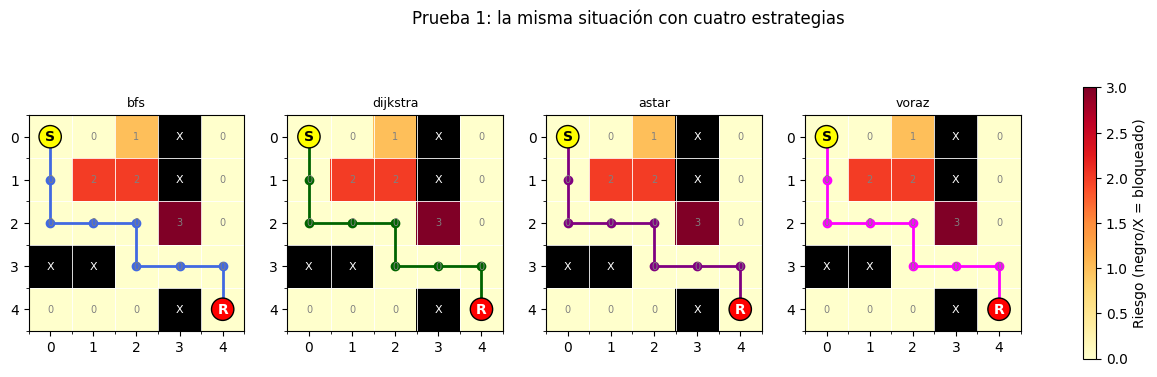

In [34]:
print("--- Prueba 1: Ruta disponible ---")
resultados_1 = {}
for alg in ALGORITMOS_DISPONIBLES:
    r = buscar_ruta_detalle(mapa_inundacion, inicio, refugio, alg)
    ok, err = validar_ruta(mapa_inundacion, r["ruta"], inicio, refugio, ALPHA, r["costo"])
    assert r["encontrada"] and ok, f"{alg} falló: {err}"
    resultados_1[alg] = r["ruta"]
    print(f"{alg:9s} pasos: {r['pasos']} | costo: {r['costo']} | expandidos: {r['expandidos']}")
print("Todas las rutas son válidas (verificado con validar_ruta).")
visualizar_comparacion(mapa_inundacion, resultados_1, "Prueba 1: la misma situación con cuatro estrategias")

Zona bloqueada añadida: se bloquea (valor -1) una celda intermedia de la ruta original. El agente debe desviar su trayectoria; la nueva ruta nunca puede costar menos que la original.

--- Prueba 2: Zona Bloqueada ---
Costo antes: 8.0 | costo después de bloquear (2, 1): 11.0


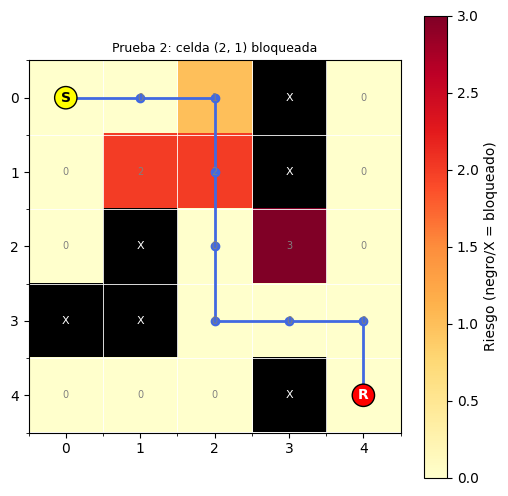

In [35]:
print("--- Prueba 2: Zona Bloqueada ---")
ruta_original = buscar_ruta_detalle(mapa_inundacion, inicio, refugio, "dijkstra")
mapa_prueba_2 = mapa_inundacion.copy()

# Bloqueamos una celda que SÍ forma parte de la ruta original y que tiene alternativa
celda_bloqueada = (2, 1)
assert celda_bloqueada in ruta_original["ruta"], "la celda elegida no estaba en la ruta original"
mapa_prueba_2[celda_bloqueada] = -1

res_2 = buscar_ruta_detalle(mapa_prueba_2, inicio, refugio, "dijkstra")
ruta_2 = res_2["ruta"]
assert res_2["encontrada"], "debería existir una ruta alternativa"
assert celda_bloqueada not in ruta_2, "la ruta nueva usa la celda bloqueada"
assert validar_ruta(mapa_prueba_2, ruta_2, inicio, refugio, ALPHA, res_2["costo"])[0]
assert res_2["costo"] >= ruta_original["costo"], "bloquear no puede reducir el costo"
print(f"Costo antes: {ruta_original['costo']} | costo después de bloquear {celda_bloqueada}: {res_2['costo']}")
visualizar_terreno(mapa_prueba_2, ruta_2, f"Prueba 2: celda {celda_bloqueada} bloqueada")

Refugio inaccesible: Si se bloquean (-1) las celdas que rodean al refugio, la función devuelve una lista vacía (sin ruta) y el sistema lo maneja de manera robusta sin colapsar.

--- Prueba 3: Refugio Inaccesible ---
Comportamiento correcto: El sistema detectó que no hay ruta posible.


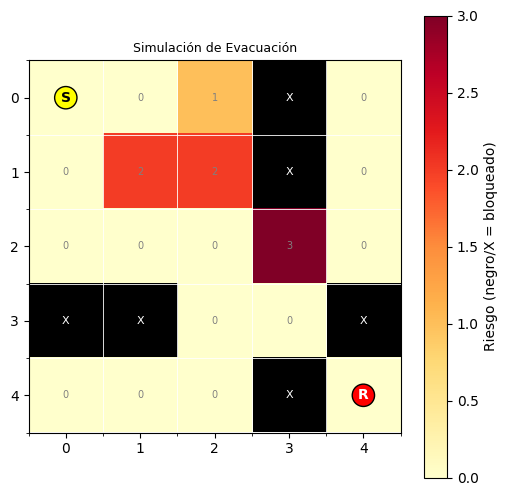

Ningún algoritmo inventa una ruta al refugio aislado.
Bloquear (2,2) deja el refugio inaccesible (cuello de botella del mapa).


In [36]:
print("--- Prueba 3: Refugio Inaccesible ---")
mapa_prueba_3 = mapa_inundacion.copy()

# Rodeamos el refugio (4,4) con zonas bloqueadas
mapa_prueba_3[3, 4] = -1
mapa_prueba_3[4, 3] = -1

ruta_3 = buscar_ruta(mapa_prueba_3, inicio, refugio, "dijkstra")
if not ruta_3:
    print("Comportamiento correcto: El sistema detectó que no hay ruta posible.")
visualizar_terreno(mapa_prueba_3, ruta_3)

# Comprobación con todos los algoritmos
for alg in ALGORITMOS_DISPONIBLES:
    r = buscar_ruta_detalle(mapa_prueba_3, inicio, refugio, alg)
    assert not r["encontrada"] and r["ruta"] == [], f"{alg} devolvió ruta a un refugio aislado"
print("Ningún algoritmo inventa una ruta al refugio aislado.")

# Hallazgo: (2,2) es un cuello de botella; bloquearlo también aísla el refugio
mapa_cuello = mapa_inundacion.copy()
mapa_cuello[2, 2] = -1
for alg in ALGORITMOS_DISPONIBLES:
    assert buscar_ruta(mapa_cuello, inicio, refugio, alg) == [], f"{alg}: (2,2) debería aislar el refugio"
print("Bloquear (2,2) deja el refugio inaccesible (cuello de botella del mapa).")

Modificación de riesgo: se eleva el riesgo de una región clave y se vuelve a buscar. La ruta cambia para evitar las celdas de mayor riesgo (aquí con el mismo número de pasos, pero con menor costo total).

--- Prueba 4: Cambio de Riesgo ---


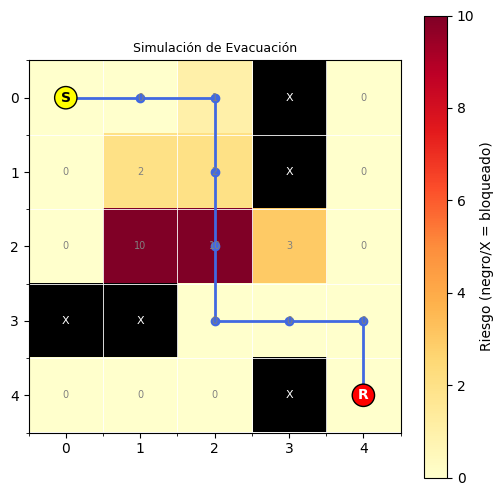

Ruta anterior evaluada con el nuevo riesgo: costo 28.0 | ruta nueva: costo 21.0


In [37]:
print("--- Prueba 4: Cambio de Riesgo ---")
mapa_prueba_4 = mapa_inundacion.copy()

# Asignamos un riesgo extremo (ej. 10) al pasillo central directo
mapa_prueba_4[2, 1] = 10
mapa_prueba_4[2, 2] = 10

ruta_4 = buscar_ruta(mapa_prueba_4, inicio, refugio, "dijkstra")
ruta_base = buscar_ruta(mapa_inundacion, inicio, refugio, "dijkstra")
visualizar_terreno(mapa_prueba_4, ruta_4)

# Comprobación: la ruta debe reaccionar al cambio de riesgo
assert ruta_4 != ruta_base, "la ruta debería cambiar al subir el riesgo"
assert not ({(2, 1)} & set(ruta_4)), "la nueva ruta debería evitar la celda (2,1) de riesgo 10"
costo_base_en_nuevo = costo_de_ruta(mapa_prueba_4, ruta_base)
costo_nuevo = costo_de_ruta(mapa_prueba_4, ruta_4)
assert costo_nuevo <= costo_base_en_nuevo
print(f"Ruta anterior evaluada con el nuevo riesgo: costo {costo_base_en_nuevo} | ruta nueva: costo {costo_nuevo}")

Error de coordenadas

In [38]:
print("--- Prueba 5: Coordenada de inicio inválida ---")
mapa_prueba_5 = mapa_inundacion.copy()

# Intentamos iniciar directamente sobre una zona inundada
inicio_invalido = (3, 0) # Esta coordenada tiene un -1

try:
    # Tu función buscar_ruta debería lanzar una alerta o retornar vacío antes de calcular
    ruta_5 = buscar_ruta(mapa_prueba_5, inicio_invalido, refugio, "dijkstra")
    print("Error: El sistema intentó calcular una ruta desde el agua.")
except Exception as e:
    print(f"Excepción controlada exitosamente: {e}")

--- Prueba 5: Coordenada de inicio inválida ---
Excepción controlada exitosamente: El punto de inicio está ubicado en una zona inundada/bloqueada (-1).


## Prueba 6: el camino más corto deja de ser el más conveniente

El mapa 5x5 es demasiado pequeño para este caso, así que se usa un mapa de 10x10 con un "río" de riesgo 3 en las columnas 2 a 7 (filas 0 a 7). Las filas 8 y 9 están secas. La ruta directa cruza el río; el rodeo es más largo pero seco.

**Respuesta a la pregunta del enunciado:** el sistema compara las rutas por **costo total** = Σ (1 + `ALPHA` × riesgo). Se demuestra con BFS (menos pasos, ignora el riesgo) frente a Dijkstra/A\* (menor costo) y con un barrido de `ALPHA`.

BFS      : 9 pasos | costo 27.0 | celdas de riesgo 3: 6
Dijkstra : 25 pasos | costo 25.0 | celdas de riesgo 3: 0
La ruta más corta NO es la más conveniente cuando se considera el riesgo.


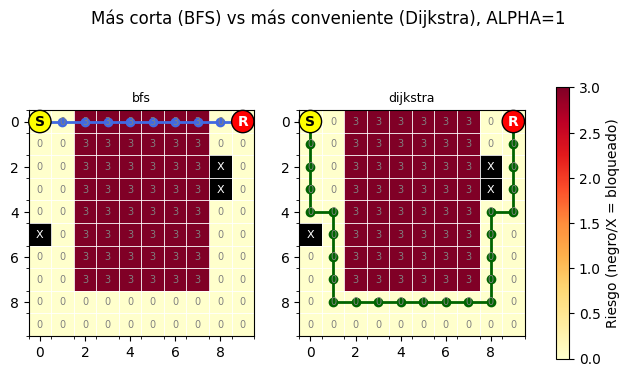

,ALPHA,pasos,costo,celdas_riesgo3
0,0.0,9,9.0,6
1,0.1,9,10.8,6
2,0.2,9,12.6,6
3,0.3,9,14.4,6
4,0.5,9,18.0,6
5,1.0,25,25.0,0
6,2.0,25,25.0,0
7,5.0,25,25.0,0


In [39]:
mapa_demo = np.zeros((10, 10), dtype=int)
mapa_demo[0:8, 2:8] = 3          # río de alto riesgo
mapa_demo[2:4, 8] = -1           # escombros cerca del refugio
mapa_demo[5, 0] = -1
ini_demo, ref_demo = (0, 0), (0, 9)

r_bfs = buscar_ruta_detalle(mapa_demo, ini_demo, ref_demo, "bfs")
r_dij = buscar_ruta_detalle(mapa_demo, ini_demo, ref_demo, "dijkstra")
celdas_riesgo3 = lambda ruta: sum(1 for p in ruta if mapa_demo[p] == 3)

for r in (r_bfs, r_dij):
    assert validar_ruta(mapa_demo, r["ruta"], ini_demo, ref_demo, ALPHA, r["costo"])[0]
assert r_bfs["pasos"] < r_dij["pasos"], "BFS debería ser más corta en pasos"
assert r_dij["costo"] < r_bfs["costo"], "Dijkstra debería tener menor costo"

print(f"BFS      : {r_bfs['pasos']} pasos | costo {r_bfs['costo']} | celdas de riesgo 3: {celdas_riesgo3(r_bfs['ruta'])}")
print(f"Dijkstra : {r_dij['pasos']} pasos | costo {r_dij['costo']} | celdas de riesgo 3: {celdas_riesgo3(r_dij['ruta'])}")
print("La ruta más corta NO es la más conveniente cuando se considera el riesgo.")
visualizar_comparacion(mapa_demo, {"bfs": r_bfs["ruta"], "dijkstra": r_dij["ruta"]},
                       "Más corta (BFS) vs más conveniente (Dijkstra), ALPHA=1", ini_demo, ref_demo)

# Barrido de ALPHA: ¿cuándo cambia la decisión?
filas = []
for a in [0, 0.1, 0.2, 0.3, 0.5, 1, 2, 5]:
    r = buscar_ruta_detalle(mapa_demo, ini_demo, ref_demo, "dijkstra", alpha=a)
    filas.append({"ALPHA": a, "pasos": r["pasos"], "costo": r["costo"], "celdas_riesgo3": celdas_riesgo3(r["ruta"])})
display(pd.DataFrame(filas))

## Prueba 7 (adicional): detectar errores de la propia implementación

Se generan **300 terrenos aleatorios** (semilla fija) con distintos `ALPHA` y se comprueban propiedades que deben cumplirse **siempre**:

1. Toda ruta devuelta es válida según el validador.
2. Si un algoritmo no encuentra ruta, ninguno la encuentra.
3. **A\* y Dijkstra dan el mismo costo** (si no, la heurística sobreestimaría).
4. Dijkstra nunca cuesta más que BFS ni que Voraz.
5. BFS nunca usa más pasos que los demás.

Después se **comprueba que la prueba sí sirve**: se usa un A\* con heurística inflada (`peso_h=5`, no admisible) y se cuenta cuántas veces la prueba lo detecta. También se prueban entradas inválidas (fuera del mapa, algoritmo desconocido).

In [40]:
def terreno_aleatorio(rng, n=12):
    g = rng.choice([-1, 0, 1, 2, 3], size=(n, n), p=[0.2, 0.35, 0.2, 0.15, 0.1])
    g[0, 0] = 0
    g[n - 1, n - 1] = 0
    return g

def revisar(g, ini, ref, alpha, peso_h_astar=1.0):
    fallos = []
    res = {
        "bfs": buscar_ruta_detalle(g, ini, ref, "bfs", alpha),
        "dijkstra": buscar_ruta_detalle(g, ini, ref, "dijkstra", alpha),
        "astar": buscar_ruta_detalle(g, ini, ref, "astar", alpha, peso_h=peso_h_astar),
        "voraz": buscar_ruta_detalle(g, ini, ref, "voraz", alpha),
    }
    for n, r in res.items():
        if r["encontrada"]:
            ok, err = validar_ruta(g, r["ruta"], ini, ref, alpha, r["costo"])
            if not ok:
                fallos.append(f"{n} ruta inválida: {err}")
    if len({r["encontrada"] for r in res.values()}) > 1:
        fallos.append("inconsistencia de alcanzabilidad entre algoritmos")
    elif res["dijkstra"]["encontrada"]:
        d, a = res["dijkstra"]["costo"], res["astar"]["costo"]
        if abs(d - a) > 1e-9:
            fallos.append("A* y Dijkstra difieren en costo")
        if d > res["bfs"]["costo"] + 1e-9:
            fallos.append("Dijkstra peor que BFS en costo")
        if d > res["voraz"]["costo"] + 1e-9:
            fallos.append("Dijkstra peor que Voraz en costo")
        if res["bfs"]["pasos"] > min(res[k]["pasos"] for k in ("dijkstra", "astar", "voraz")):
            fallos.append("BFS usó más pasos que otro algoritmo")
    return fallos, res

ALPHAS = [0, 0.5, 1, 2]
rng = np.random.default_rng(2024)
fallos_totales, sin_ruta = [], 0
expandidos = {a: [] for a in ALGORITMOS_DISPONIBLES}
for i in range(300):
    g = terreno_aleatorio(rng)
    fallos, res = revisar(g, (0, 0), (11, 11), ALPHAS[i % len(ALPHAS)])
    if fallos:
        fallos_totales.append((i, fallos))
    if res["dijkstra"]["encontrada"]:
        for n, r in res.items():
            expandidos[n].append(r["expandidos"])
    else:
        sin_ruta += 1
assert not fallos_totales, f"Se encontraron fallos: {fallos_totales[:3]}"
print(f"300 terrenos revisados, 0 fallos. Terrenos sin ruta posible: {sin_ruta}.")
print("Promedio de nodos expandidos (terrenos con ruta):")
print(pd.Series({n: round(float(np.mean(v)), 2) for n, v in expandidos.items()}).to_string())

# La prueba debe delatar un A* defectuoso (heurística no admisible)
rng = np.random.default_rng(2024)
detectados = 0
for i in range(300):
    g = terreno_aleatorio(rng)
    fallos, _ = revisar(g, (0, 0), (11, 11), ALPHAS[i % len(ALPHAS)], peso_h_astar=5.0)
    if any("difieren en costo" in f for f in fallos):
        detectados += 1
print(f"\nA* con heurística inflada: la prueba lo detectó en {detectados} de 300 terrenos.")
assert detectados > 0, "la prueba no detecta un A* defectuoso: no sirve"

# Entradas inválidas
for args, esperado in [
    ((mapa_inundacion, (9, 9), refugio, "dijkstra"), "fuera del mapa"),
    ((mapa_inundacion, inicio, (0, 7), "dijkstra"), "fuera del mapa"),
    ((mapa_inundacion, inicio, refugio, "magia"), "desconocido"),
]:
    try:
        buscar_ruta(*args)
        raise AssertionError("debió lanzar ValueError")
    except ValueError as e:
        assert esperado in str(e)
print("Entradas inválidas: se rechazan con ValueError.")

300 terrenos revisados, 0 fallos. Terrenos sin ruta posible: 40.
Promedio de nodos expandidos (terrenos con ruta):
bfs         114.10
dijkstra    112.02
astar        89.00
voraz        28.30

A* con heurística inflada: la prueba lo detectó en 174 de 300 terrenos.
Entradas inválidas: se rechazan con ValueError.


# Comparación de resultados

Todos los valores de las tablas salen de **ejecuciones reales** de este cuaderno. El tiempo es la **mediana de 100 repeticiones**. "Trabajo" = nodos expandidos y generados.

In [41]:
def tabla_comparacion(mapa, ini, ref, alpha=ALPHA, reps=100):
    filas = []
    for alg in ALGORITMOS_DISPONIBLES:
        runs = [buscar_ruta_detalle(mapa, ini, ref, alg, alpha) for _ in range(reps)]
        r = runs[0]
        assert not r["encontrada"] or validar_ruta(mapa, r["ruta"], ini, ref, alpha, r["costo"])[0]
        filas.append({"algoritmo": alg, "encontrada": r["encontrada"], "pasos": r["pasos"],
                      "costo": r["costo"], "expandidos": r["expandidos"],
                      "generados": r["generados"], "max_frontera": r["max_frontera"],
                      "tiempo_ms (mediana)": round(float(np.median([x["tiempo_ms"] for x in runs])), 4)})
    return pd.DataFrame(filas).set_index("algoritmo")

print("Mapa 5x5, ALPHA = 1")
display(tabla_comparacion(mapa_inundacion, inicio, refugio, 1.0))
print("\nMapa 10x10 con río, ALPHA = 1 (el riesgo importa)")
t_demo1 = tabla_comparacion(mapa_demo, ini_demo, ref_demo, 1.0)
display(t_demo1)
print("\nMapa 10x10 con río, ALPHA = 0 (solo distancia)")
display(tabla_comparacion(mapa_demo, ini_demo, ref_demo, 0.0))

Mapa 5x5, ALPHA = 1


,encontrada,pasos,costo,expandidos,generados,max_frontera,tiempo_ms (mediana)
algoritmo,,,,,,,
bfs,True,8,8.0,19,20,3,0.0653
dijkstra,True,8,8.0,18,19,4,0.1434
astar,True,8,8.0,11,17,7,0.1170
voraz,True,8,8.0,10,16,7,0.1072



Mapa 10x10 con río, ALPHA = 1 (el riesgo importa)


,encontrada,pasos,costo,expandidos,generados,max_frontera,tiempo_ms (mediana)
algoritmo,,,,,,,
bfs,True,9,27.0,52,61,12,0.1488
dijkstra,True,25,25.0,91,97,14,0.9647
astar,True,25,25.0,57,84,28,0.6092
voraz,True,9,27.0,10,19,10,0.1127



Mapa 10x10 con río, ALPHA = 0 (solo distancia)


,encontrada,pasos,costo,expandidos,generados,max_frontera,tiempo_ms (mediana)
algoritmo,,,,,,,
bfs,True,9,9.0,52,61,12,0.1389
dijkstra,True,9,9.0,52,61,12,0.6027
astar,True,9,9.0,10,19,10,0.2219
voraz,True,9,9.0,10,19,10,0.2038


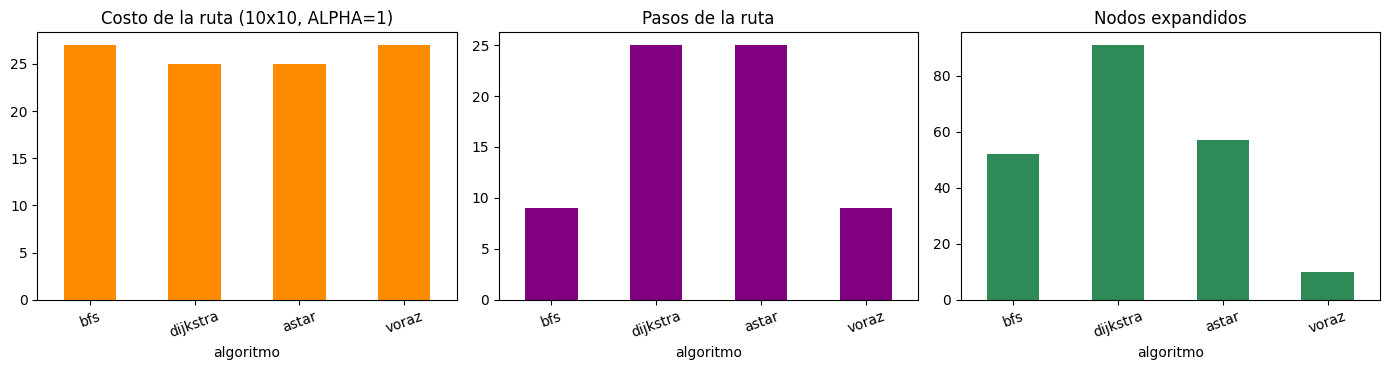

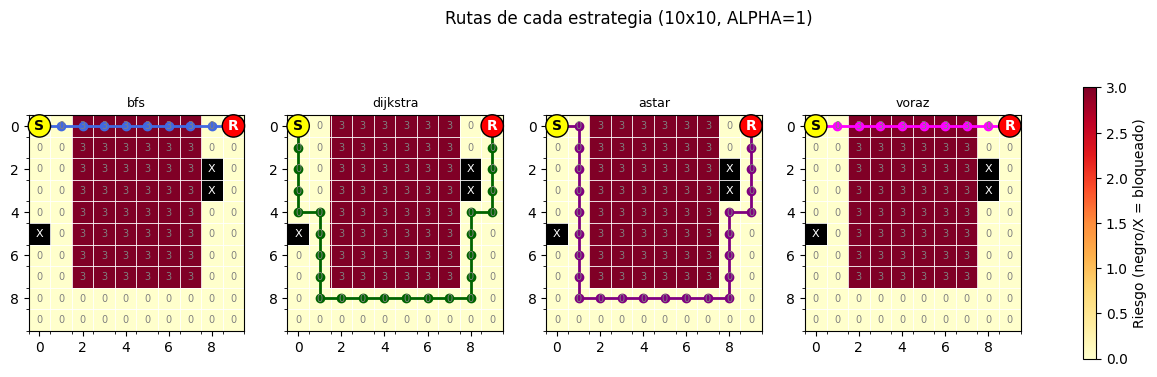

In [42]:
fig, axs = plt.subplots(1, 3, figsize=(14, 3.8))
t_demo1["costo"].plot.bar(ax=axs[0], color="darkorange"); axs[0].set_title("Costo de la ruta (10x10, ALPHA=1)")
t_demo1["pasos"].plot.bar(ax=axs[1], color="purple"); axs[1].set_title("Pasos de la ruta")
t_demo1["expandidos"].plot.bar(ax=axs[2], color="seagreen"); axs[2].set_title("Nodos expandidos")
for ax in axs:
    ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

rutas_demo = {a: buscar_ruta(mapa_demo, ini_demo, ref_demo, a, 1.0) for a in ALGORITMOS_DISPONIBLES}
visualizar_comparacion(mapa_demo, rutas_demo, "Rutas de cada estrategia (10x10, ALPHA=1)", ini_demo, ref_demo)

### Cómo leer las comparaciones
- **BFS** minimiza pasos pero **ignora el riesgo**: con `ALPHA > 0` puede salir más cara que Dijkstra.
- **Dijkstra** garantiza el menor costo; **A\*** obtiene el mismo costo (lo confirma la Prueba 7) y suele expandir menos nodos porque la heurística lo guía al refugio.
- **Voraz** expande pocos nodos pero **no garantiza** una ruta óptima.
- Con `ALPHA = 0` el riesgo no influye y la ruta corta cruza el río; al subir `ALPHA`, el sistema prefiere el rodeo seco (ver el barrido en la Prueba 6).
- Las cifras concretas están en las tablas de arriba, generadas en esta ejecución.

# Historial de Cambios (Git) y Declaración de IA
se agrego Comparación de resultados donde esta mostrando los resultados.

se corrigio y se hizo modificaciones a Pruebas y Casos Requeridos con ayuda de daisy y sidney hicieron las correcciones de la 5 a la 7 y yo las primeras 4.

se modico el codigo de Simulación de Rutas en Zona Inundada por venus.

implementación completa de algoritmos Dijkstra y BFS con métricas de costo y validación de inicio.

feat: implementación completa de algoritmos Dijkstra y BFS con métricas de costo y validación de inicio

Se creó con Colab

Casos de prueba agregados

Se creó con Colab